# This code is for the simulation of Acetyl-CoA, Malonyl-CoA FA, TG model for different initial conditions.
The code serve to test the multistability in the "blind way". Indeed for a fix values of parameters, we varies initial conditions randomly and observe the steady state.
<div>
<img src="ACetyl_CoA_TAG_V2.png" width="500"/>
</div>



In [1]:
import numpy as np
import random as rd
import pandas as pd
import scipy.integrate as sp
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from Rate_laws import *
from sklearn.manifold import TSNE
import seaborn as sn

In [2]:
# Default parameters for the model.

par = {
    "k1": 1.0,
    "k2": 1.0,
    "k3": 1.0,
    "alpha": 1.0,
    "beta": 1.0,
    "gamma": 1.0,
    "V1": 1.0,
    "V2": 1.0,
    "V3": 1.0,
    "V4": 1.0,
    "V5": 1.0,
    "Km1": 1.0,
    "Km2": 1.0,
    "Km3": 1.0,
    "Km4": 1.0,
    "Km5": 1.0,
    "q1": 2.0,
    "q4": 1.0,
    #"y0": 1.0
}

In [3]:
# In this part we define the rate equations for each reactions 

compounds = ["Acetyl_CoA", "Malonyl_CoA", "Fatty_Acyl", "TAG"]

n_compounds = len(compounds)


def get_rates(y, par):
    Acetyl_CoA, Malonyl_CoA, Fatty_Acyl, TAG = y

    reactions = {
        "v_in_1":
        constant_influx(par["k1"]),
        "v_in_2":
        constant_influx(par["k2"]),

        # "v_in_3": constant_influx(par["Kin3"]),
        "v_in_3":
        constant_influx(par["k3"]),
        "r1":
        non_competitive_inhibition(par["V1"], par["Km1"], par["q1"],
                                   Acetyl_CoA, Fatty_Acyl),
        "r2":
        michaelis_meten(par["V2"], par["Km2"], Malonyl_CoA),
        "r3":
        michaelis_meten(par["V3"], par["Km3"], Fatty_Acyl),
        "r4":
        non_competitive_inhibition(par["V4"], par["Km4"], par["q4"],
                                   Fatty_Acyl, Malonyl_CoA),
        "r5":
        michaelis_meten(par["V5"], par["Km5"], TAG),
        "v_out1":
        mass_action_law(par["alpha"], Acetyl_CoA),
        "v_out2":
        mass_action_law(par["beta"], Fatty_Acyl),
        "v_out3":
        mass_action_law(par["gamma"], TAG),
    }
    return reactions

In [4]:
# The individual reactions are put together to describe the dynamic of the system as ODE

def model(time, y, par):
    rates = get_rates(y=y, par=par)
    d_Acetyl_CoA_dt = (rates["v_in_1"] - rates["r1"] + rates["r4"] -
                       rates["v_out1"])
    d_Malony_CoA = rates["r1"] - rates["r2"]

    d_Fatty_Acyl = (rates["v_in_2"] + rates["r2"] - rates["r3"] - rates["r4"] +
                    rates["r5"] - rates["v_out2"])

    d_TAG_dt = rates["v_in_3"] + rates["r3"] - rates["r5"] - rates["v_out3"]

    return np.array([d_Acetyl_CoA_dt, d_Malony_CoA, d_Fatty_Acyl, d_TAG_dt])

In [5]:
# Time points for ploting the time course

#y0= np.zeros(n_compounds)
#y0 = par["y0"]

time = np.linspace(0, 10, 100)



In [6]:
# Selection of random initial conditions and plot,solve the system for the selected initial conditions

# Plot the corresponding solutions
lower = 0
upper = 10


def select_initial_cond(lower, uper):
    y0 = [rd.uniform(lower, upper) for i in range(4)]
    y0 = np.array(y0)
    return y0

In [7]:

# Solve the differential equations 
# Take a look at these results first, before you run the steady state 

#y = sp.odeint(func=model, y0=y0, t=time, args=(par, ), tfirst=True)

In [8]:
### Simulate the steady-state function as function of parameters
def simulate_steady_state(model, y0, par, dt=1e-3, error=1e-5, max_steps=1e8):
    r = sp.ode(model)
    r.set_integrator("lsoda", method="bdf")
    r.set_f_params(par)
    r.set_initial_value(y0, 0.0)

    y1 = y0.copy()
    nsteps = 0
    while r.successful and nsteps < max_steps:
        y2 = r.integrate(r.t + dt)
        if np.linalg.norm(y1 - y2, ord=2) < error:
            return y2
        else:
            y1 = y2
        nsteps += 1
    raise ValueError("Maximal simulation steps exceeded")
#steady =  list(simulate_steady_state(model,y0, par, dt=100))
    

In [9]:
#select random parameters
# this function is used to select parameters randomly
low = 0.0
high = 10.0

def select_par(low, par, size =18):
    list_par = list(np.random.uniform(low, high, size=18))
    return list_par

par = {key: value for key, value in zip(par.keys(), select_par(low, high))}

lower = 0
upper = 1000
steady = []
for i in range(100):
    y0 = select_initial_cond(lower, upper)
    sol = list(simulate_steady_state(model,y0, par, dt=100))
    steady.append(sol)
    print (y0, sol)
steady = np.array(steady)

[ 62.50861995 778.85597995  51.79699775 114.46962698] [0.9404841956712328, 0.060181879233843015, 5.198922094276999, 1.7835670721142942]
[593.57437822 883.09444868 893.4886206  727.07780776] [0.9404841940904469, 0.060181881626647116, 5.198922129460961, 1.7835670758573319]
[495.61933978 268.46820038 441.14070042  66.53365511] [0.940484194616487, 0.060181880831064107, 5.198922117790965, 1.7835670746163501]
[669.61051845 111.91582397 927.83268923  53.21854563] [0.9404841936360366, 0.06018188231441752, 5.1989221395712955, 1.783567076932878]
[375.87608872 682.89262792 938.98598286 847.62290493] [0.9404841942131189, 0.060181881440689894, 5.198922126731732, 1.783567075566432]
[918.12248987 739.64896819 189.68874253 652.79651589] [0.9404841940703343, 0.06018188165709684, 5.198922129908934, 1.7835670759049933]
[794.19737059 124.59339709 540.76767965 185.35372564] [0.9404841943216193, 0.06018188127610265, 5.198922124280387, 1.7835670753057111]
[131.85461715 795.56000591  72.54043361 506.54946928]

[211.31479077 779.48309697 192.88200544 521.57900131] [0.9404841940956081, 0.06018188161883103, 5.198922129345892, 1.783567075845087]
[250.53911869 459.32190296 809.23109325 499.80953704] [0.9404841940952363, 0.06018188161939833, 5.198922129354393, 1.7835670758459947]
[676.85797235 794.52058425 249.30231844 383.64701715] [0.9404841940902782, 0.06018188162690436, 5.198922129464817, 1.783567075857743]
[563.94824905 693.75231657 776.85589579 407.43605056] [0.9404841977889385, 0.06018187602601695, 5.19892204701364, 1.7835670670844044]
[714.85790688 803.44474656 974.09984654 566.99720164] [0.9404841954126401, 0.060181879624530615, 5.198922099990674, 1.783567072721565]
[767.96004472 368.64089155 943.14388339 265.46358898] [0.940484194089824, 0.06018188162759181, 5.19892212947493, 1.783567075858819]
[518.10473859  94.24183878 332.00186495 795.66850421] [0.940484194097514, 0.06018188161594975, 5.198922129303668, 1.783567075840598]
[425.24294017 623.04449431 644.13959221 257.16478908] [0.940484

/home/chilperic/anaconda3/lib/python3.7/site-packages/scipy/integrate/_ode.py:1348: UserWarning: lsoda: Excess work done on this call (perhaps wrong Dfun type).
  self.messages.get(istate, unexpected_istate_msg)))


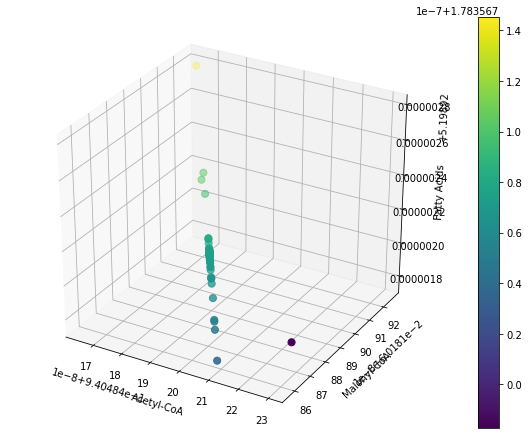

In [10]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
sp = ax.scatter(steady[:,0],steady[:,1],steady[:,2], s=50, c=steady[:,3])
ax.set_xlabel('Acetyl-CoA')
ax.set_ylabel('Malonyl-CoA')
ax.set_zlabel('Fatty Acids')
plt.tight_layout()
plt.savefig("steady.png", bbox_inches='tight')
plt.colorbar(sp)
plt.show()

In [11]:
par

{'k1': 7.0632770234976086,
 'k2': 7.3825783633871165,
 'k3': 3.662466559292313,
 'alpha': 9.831301124325586,
 'beta': 0.29917008244232934,
 'gamma': 4.0967209858594025,
 'V1': 0.4103433106581589,
 'V2': 1.4777344651194468,
 'V3': 8.818139282314966,
 'V4': 4.294867941692045,
 'V5': 0.8328982823178555,
 'Km1': 8.394591379908071,
 'Km2': 6.430658688927164,
 'Km3': 6.806848936091738,
 'Km4': 2.6163413739746053,
 'Km5': 6.741463957325999,
 'q1': 0.3880244829722046,
 'q4': 4.996017031837901}

In [12]:
df = pd.DataFrame(data=steady, index=None, columns=["Acetyl-CoA", "Malonyl-CoA", "Fatty_Acids","Triglycerides" ])
df

,Acetyl-CoA,Malonyl-CoA,Fatty_Acids,Triglycerides
0,0.940484,0.060182,5.198922,1.783567
1,0.940484,0.060182,5.198922,1.783567
2,0.940484,0.060182,5.198922,1.783567
3,0.940484,0.060182,5.198922,1.783567
4,0.940484,0.060182,5.198922,1.783567
...,...,...,...,...
95,0.940484,0.060182,5.198922,1.783567
96,0.940484,0.060182,5.198922,1.783567
97,0.940484,0.060182,5.198922,1.783567
98,0.940484,0.060182,5.198922,1.783567


In [13]:
df.shape

(100, 4)

In [14]:
#non_numeric = ["Acetyl-CoA", "Malonyl-CoA", "Fatty_Acids","Triglycerides" ]
df_non_numeric = df
df_non_numeric

,Acetyl-CoA,Malonyl-CoA,Fatty_Acids,Triglycerides
0,0.940484,0.060182,5.198922,1.783567
1,0.940484,0.060182,5.198922,1.783567
2,0.940484,0.060182,5.198922,1.783567
3,0.940484,0.060182,5.198922,1.783567
4,0.940484,0.060182,5.198922,1.783567
...,...,...,...,...
95,0.940484,0.060182,5.198922,1.783567
96,0.940484,0.060182,5.198922,1.783567
97,0.940484,0.060182,5.198922,1.783567
98,0.940484,0.060182,5.198922,1.783567


In [15]:
m = TSNE(learning_rate =50)

In [16]:
tsne_features = m.fit_transform(df_non_numeric)

In [17]:
tsne_features[1:4,:]

array([[-3.1400619 , -2.0865731 ],
       [-3.2263188 ,  0.10631947],
       [-2.9747386 , -0.73630595]], dtype=float32)

In [18]:
df["x"] =tsne_features[:,0]
df["y"] =tsne_features[:,1]

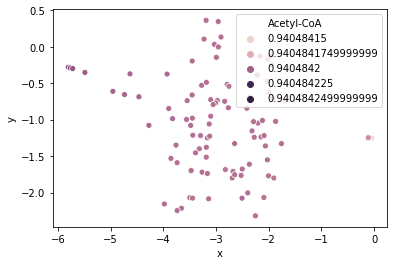

In [19]:
sn.scatterplot(x = "x", y = "y", hue= 'Acetyl-CoA',data =df)

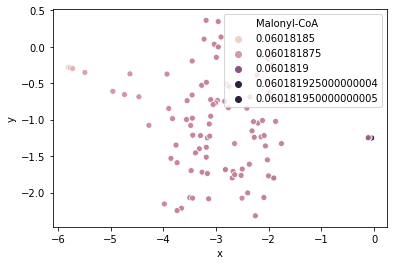

In [20]:
sn.scatterplot(x = "x", y = "y", hue= 'Malonyl-CoA',data =df)

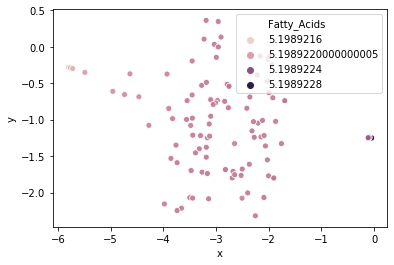

In [21]:
sn.scatterplot(x = "x", y = "y", hue= 'Fatty_Acids',data =df)

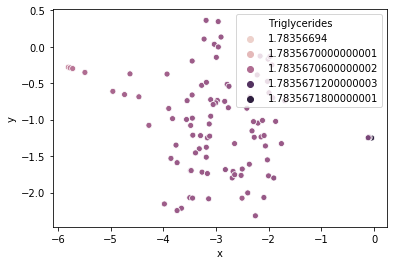

In [22]:
sn.scatterplot(x = "x", y = "y", hue= 'Triglycerides',data =df)